In [ ]:
3. Exploratory Data Analysis

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

PROCESSED_DIR = Path("../data/processed")
FIGURES_DIR = Path("../reports/figures")
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid")


def save_figure(fig, name):
    """Save a figure in reports/figures for the presentation."""
    fig.savefig(FIGURES_DIR / f"{name}.png", dpi=150, bbox_inches="tight")

In [ ]:
# sns.set_theme apply to every graph the seaborn theme.
# save_figure save the graphs as images in the figure folder (in order to use them in the presentation).

In [4]:
df_accidents = pd.read_csv(PROCESSED_DIR / "municipalities_accidents.csv",
                           dtype={"REF_AREA": str})

df_mun = pd.read_csv(PROCESSED_DIR / "municipalities_indicators.csv",
                     dtype={"REF_AREA": str, "COD_REG": str},
                     na_values=[""])

AREA_NAMES = {1: "North-West", 2: "North-East", 3: "Centre", 4: "South", 5: "Islands"}
df_mun["macro_area"] = df_mun["COD_RIP"].astype(int).map(AREA_NAMES)
df_mun["is_provincial_capital"] = df_mun["CC_UTS"].astype(int) == 1

print(df_mun.shape)
df_mun["macro_area"].value_counts()

(7900, 20)


macro_area
North-West    2991
South         1783
North-East    1390
Centre         968
Islands        768
Name: count, dtype: int64

In [ ]:
# Let's see the national trend through the years.

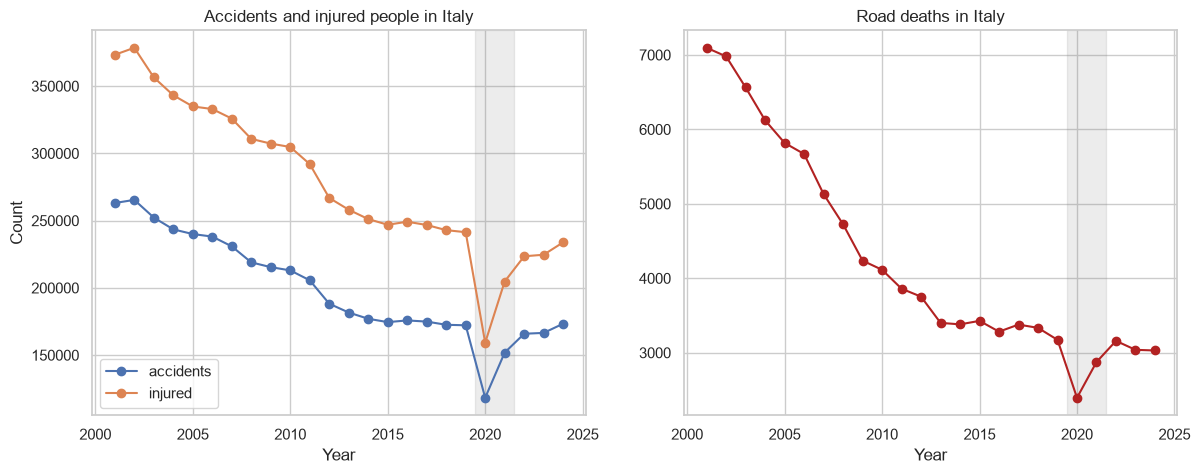

Change 2001-2023 (%):
accidents   -36.7
injured     -39.8
deaths      -57.2
dtype: float64


In [5]:
national = df_accidents.groupby("TIME_PERIOD")[["accidents", "injured", "deaths"]].sum()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

national[["accidents", "injured"]].plot(ax=ax1, marker="o")
ax1.set_title("Accidents and injured people in Italy")
ax1.set_xlabel("Year")
ax1.set_ylabel("Count")

national["deaths"].plot(ax=ax2, marker="o", color="firebrick", legend=False)
ax2.set_title("Road deaths in Italy")
ax2.set_xlabel("Year")

for ax in (ax1, ax2):
    ax.axvspan(2019.5, 2021.5, color="grey", alpha=0.15)  # Covid restrictions

save_figure(fig, "01_national_trend")
plt.show()

change = (national.loc[2023] / national.loc[2001] - 1) * 100
print("Change 2001-2023 (%):")
print(change.round(1))

In [ ]:
# As we can see, there's a clear decreasing trend in the number of accidents, injured and deaths in Italy. 
# The decrease is more pronounced for deaths, which have decreased by 60% from 2001 to 2023. 
# The decrease is less pronounced for accidents and injured, which have decreased by 30% and 40% respectively. 
# The Covid-19 pandemic has also had an impact on the number of accidents, injured and deaths, with a sharp decrease in 2020 and a partial recovery in 2021.

In [ ]:
# Distributions and skewness

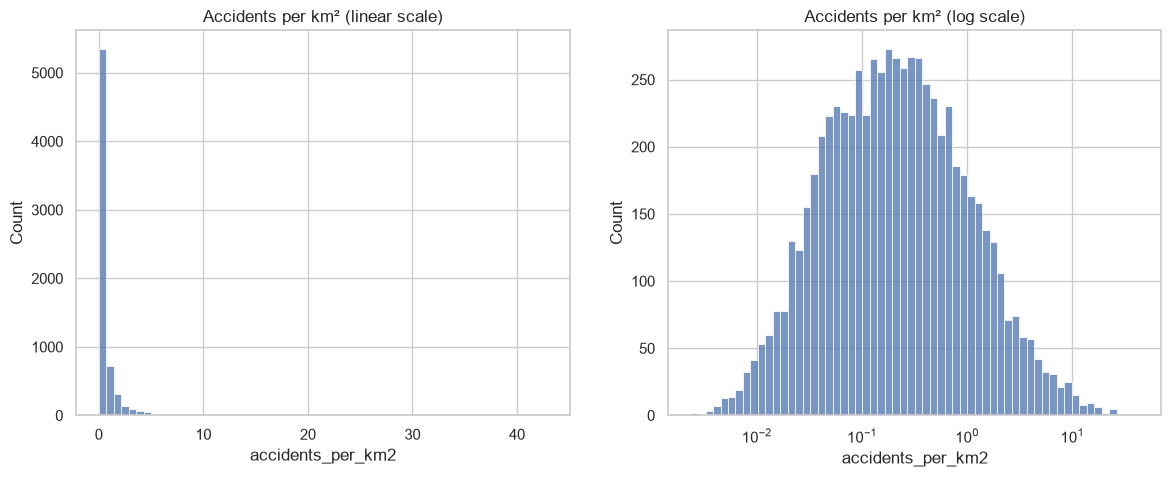

Skewness:
accidents_per_1000_inh      5.29
accidents_per_km2           8.19
deaths_per_100_accidents    6.74
dtype: float64


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

positive_density = df_mun.loc[df_mun["accidents_per_km2"] > 0, "accidents_per_km2"]

sns.histplot(positive_density, bins=60, ax=axes[0])
axes[0].set_title("Accidents per km² (linear scale)")

sns.histplot(positive_density, bins=60, log_scale=True, ax=axes[1])
axes[1].set_title("Accidents per km² (log scale)")

save_figure(fig, "02_density_distribution")
plt.show()

indicators = ["accidents_per_1000_inh", "accidents_per_km2", "deaths_per_100_accidents"]
print("Skewness:")
print(df_mun[indicators].skew().round(2))

In [ ]:
# We compared the distribution of accidents per km² on a linear and logarithmic scale. 
# The logarithmic scale shows a more normal distribution, while the linear scale shows a right-skewed distribution. 
# This indicates that there are a few municipalities with very high accident density, which skews the distribution to the right. 
# The skewness values for the three indicators are all positive, indicating right-skewed distributions.

In [ ]:
# Rates by macro-area

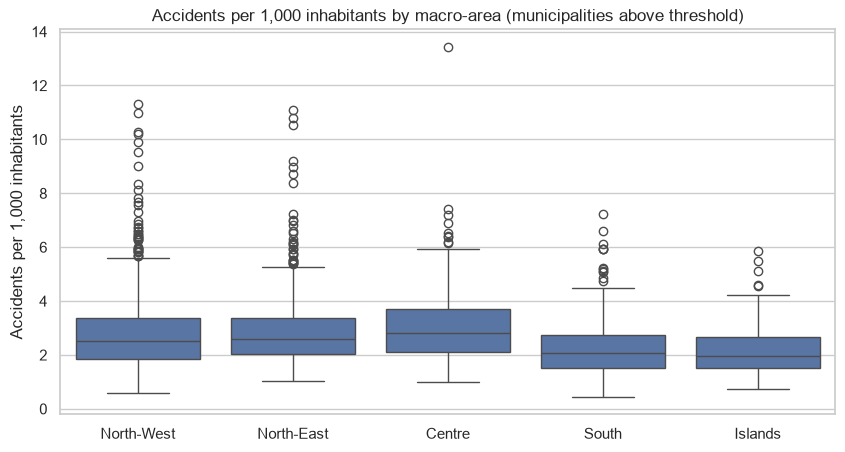

In [7]:
above = df_mun[df_mun["above_threshold"]]
area_order = list(AREA_NAMES.values())

fig, ax = plt.subplots(figsize=(10, 5))
sns.boxplot(data=above, x="macro_area", y="accidents_per_1000_inh",
            order=area_order, ax=ax)
ax.set_title("Accidents per 1,000 inhabitants by macro-area (municipalities above threshold)")
ax.set_xlabel("")
ax.set_ylabel("Accidents per 1,000 inhabitants")

save_figure(fig, "03_rate_by_area")
plt.show()

In [ ]:
# The line inside the box is the median, the box contains the middle half of the municipalities (from the 25th to the 75th percentile).
# The whiskers extend to the values still considered normal, and the isolated points beyond the whiskers are outliers.

In [8]:
def aggregate_rates(df, group_col):
    """Sum accidents, people and area by group, then compute the rates on the totals."""
    totals = df.groupby(group_col)[["accidents", "injured", "deaths", "POP_RES", "AREA_KMQ"]].sum()
    totals["accidents_per_1000_inh"] = totals["accidents"] / totals["POP_RES"] * 1000
    totals["accidents_per_km2"] = totals["accidents"] / totals["AREA_KMQ"]
    totals["deaths_per_100_accidents"] = totals["deaths"] / totals["accidents"] * 100
    return totals.round(2)


aggregate_rates(df_mun, "macro_area").reindex(area_order)

,accidents,injured,deaths,POP_RES,AREA_KMQ,accidents_per_1000_inh,accidents_per_km2,deaths_per_100_accidents
macro_area,,,,,,,,
North-West,47080.5,61803.0,662.5,15895694,57928.28,2.96,0.81,1.41
North-East,36055.0,47079.5,743.5,11581472,62395.04,3.11,0.58,2.06
Centre,42343.5,55533.0,693.0,11711089,58039.34,3.62,0.73,1.64
South,26738.5,39523.5,661.5,13415163,73803.09,1.99,0.36,2.47
Islands,13989.0,20115.0,338.5,6367812,49943.82,2.20,0.28,2.42


In [ ]:
# We can see that in the North-West area there are more accidents per km² than the other areas, but the deaths per 100 accident is the lowest.

In [9]:
def aggregate_rates(df, group_col):
    """Sum accidents, people and area by group, then compute the rates on the totals."""
    totals = df.groupby(group_col)[["accidents", "injured", "deaths", "POP_RES", "AREA_KMQ"]].sum()
    totals["accidents_per_1000_inh"] = totals["accidents"] / totals["POP_RES"] * 1000
    totals["accidents_per_km2"] = totals["accidents"] / totals["AREA_KMQ"]
    totals["deaths_per_100_accidents"] = totals["deaths"] / totals["accidents"] * 100
    return totals.round(2)


aggregate_rates(df_mun, "is_provincial_capital")

,accidents,injured,deaths,POP_RES,AREA_KMQ,accidents_per_1000_inh,accidents_per_km2,deaths_per_100_accidents
is_provincial_capital,,,,,,,,
False,90977.0,127554.0,2300.5,41442634,282656.51,2.20,0.32,2.53
True,75229.5,96500.0,798.5,17528596,19453.06,4.29,3.87,1.06


In [ ]:
# As we expected, provincial capitals have more accidents per km² than the other municipalities, but the deaths per 100 accident is lower, because you drive slower in the big cities.

In [ ]:
# Correlation matrix

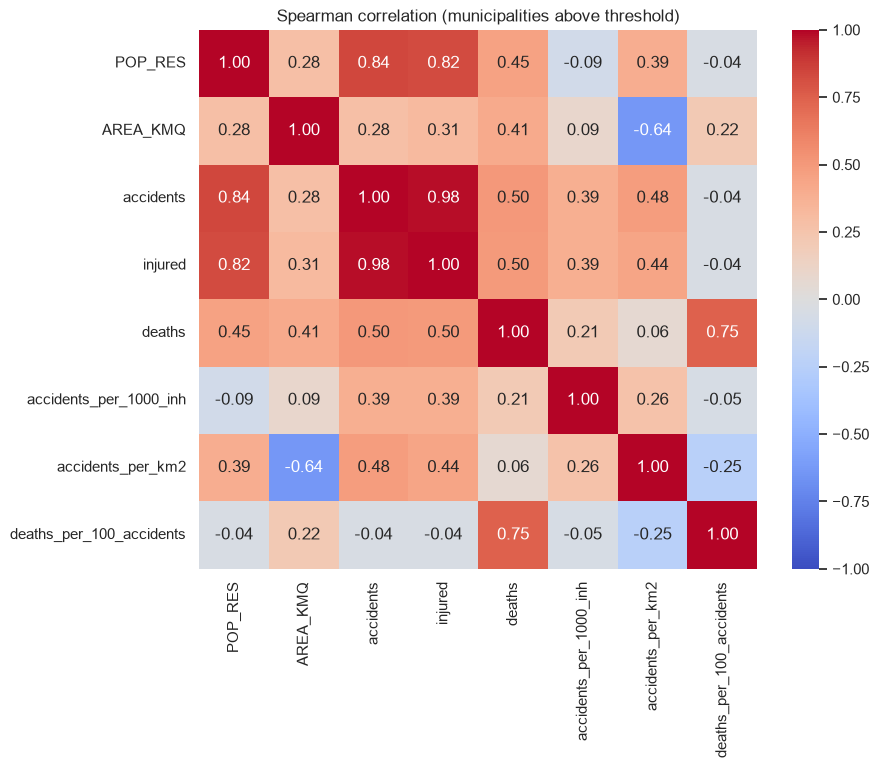

In [10]:
corr_cols = ["POP_RES", "AREA_KMQ", "accidents", "injured", "deaths",
             "accidents_per_1000_inh", "accidents_per_km2", "deaths_per_100_accidents"]

corr = above[corr_cols].corr(method="spearman")

fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax)
ax.set_title("Spearman correlation (municipalities above threshold)")

save_figure(fig, "04_correlation_matrix")
plt.show()

In [ ]:
# Correlation measures how closely two variables move together: +1 if they always increase together, −1 if one decreases when the other increases, 0 if there is no relationship.
# We used Spearman correlation instead of the classic Pearson correlation: Spearman compares the rank of the municipalities rather than their raw values, so it is not distorted by the outliers and skewed distributions we have seen.
# This matrix shows which variables are almost duplicates and, therefore, which ones make sense to use together in the clustering.

In [ ]:
# Conclusions:

# 1. Accidents have been decreasing since 2001 by 37% and deaths even more (57%), but improvements have stalled since around 2013.
# 2. The 2024 data turned out to be complete, with a total in line with the official figure.
# 3. All indicators are strongly right-skewed.
# 4. The Centre and the North have more accidents, while the South and the Islands have more severe ones; 
#    provincial capitals have 4,29 accidents per 1000 inhabitants versus 2,20, but 1,06 deaths per 100 accidents versus 2,53.
# 5. Accidents and injured people are almost duplicates, while the rate per inhabitant, density and severity are three distinct dimensions.